In [2]:
library(tidyverse)
library(DESeq2)
library(tximport)
library(rtracklayer)
library(RColorBrewer)
library(ggrepel)
sessionInfo()

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] ggrepel_0.9.6               RColorBrewer_1.1-3         
 [3] rtracklayer_1.58.0          tximport_1.26.1            
 [5] DESeq2_1.38.3               SummarizedExperiment_1.28.0
 [7] Biobase_2.58.0              MatrixGenerics_1.10.0      
 [9] matrixStats_1.4.1           Gen

In [3]:
dir <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h"

files <- list.files(dir, pattern="genes.results", full.name=TRUE)
files

[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_brm_r1_anno_rsem.genes.results"     
[2] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_brm_r2_anno_rsem.genes.results"     
[3] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_brm_tnf_r1_anno_rsem.genes.results" 
[4] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_brm_tnf_r2_anno_rsem.genes.results" 
[5] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_dmso_r1_anno_rsem.genes.results"    
[6] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_dmso_r2_anno_rsem.genes.results"    
[7] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_dmso_tnf_r1_anno_rsem.genes.results"
[8] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/BAFinh_30h/rep1_dmso_tnf_r2_anno_rsem.genes.results"

In [7]:
#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz"
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed", header=F, sep='\t')

In [8]:
#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

In [10]:
#make coldata
col.data <- data.frame(Condition=c("BRM", "BRM", "BRM", "BRM","DMSO", "DMSO", "DMSO", "DMSO"),
              Replicate=c(1,2,3,4,1,2,3,4))

In [11]:
#read in RSEM data
txi <- tximport(files=files, type="rsem", txIn=FALSE, txOut=FALSE)


reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 




In [12]:
#filter txi object
nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 78724

[1] 14385

[1] 14385

[1] 14385

In [14]:
dds <- DESeqDataSetFromTximport(txi=txi, colData=col.data, design = ~Condition)
des <- DESeq(dds)
res <- results(des, contrast=c("Condition", "BRM", "DMSO"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



using 'avgTxLength' from assays(dds), correcting for library size

Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


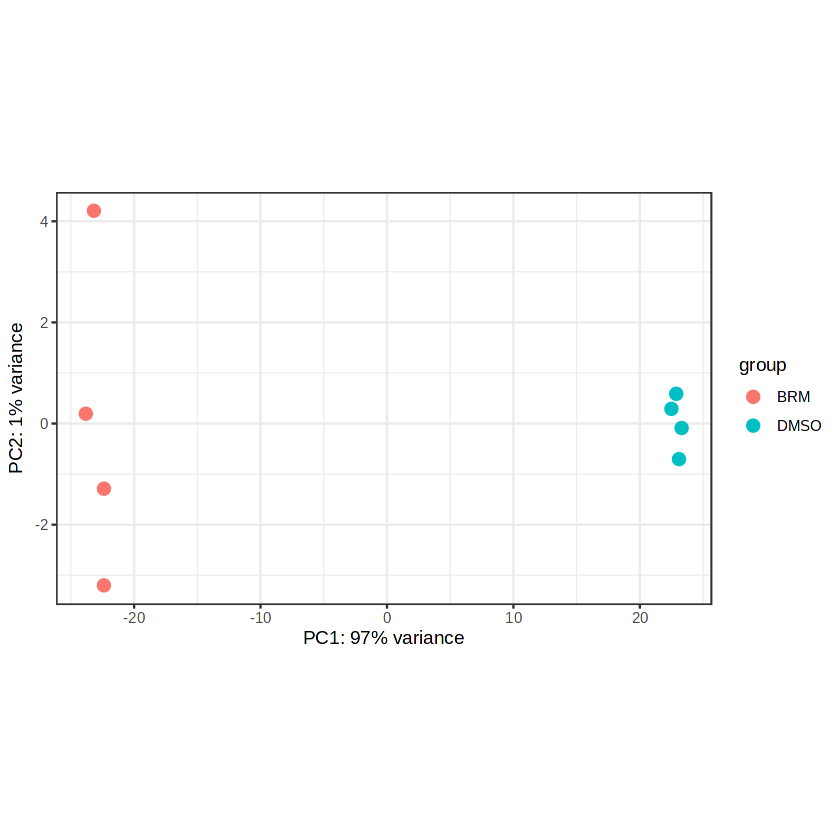

In [21]:
vsd <- vst(dds, blind=TRUE)
plotPCA(vsd, intgroup="Condition") + theme_bw() + coord_fixed(ratio=4)

In [39]:
res <- res %>% data.frame() %>% mutate(gene=row.data$gene_name,
                                       change=case_when(log2FoldChange < -log2(1.5) & padj < .05 ~ "down", 
                                                   log2FoldChange > log2(1.5) & padj < .05 ~ "up",
                                                   TRUE ~ "ns")) %>% na.omit()
summary(res)

    baseMean        log2FoldChange          lfcSE              stat         
 Min.   :     0.1   Min.   :-9.646434   Min.   :0.02129   Min.   :-87.6105  
 1st Qu.:    70.0   1st Qu.:-0.447747   1st Qu.:0.06847   1st Qu.: -3.7465  
 Median :   419.7   Median : 0.026359   Median :0.10710   Median :  0.1721  
 Mean   :  1254.9   Mean   :-0.001524   Mean   :0.26695   Mean   : -0.8321  
 3rd Qu.:  1174.3   3rd Qu.: 0.488477   3rd Qu.:0.24685   3rd Qu.:  3.0699  
 Max.   :336638.6   Max.   : 6.981459   Max.   :3.53381   Max.   : 49.6933  
     pvalue               padj             change              gene          
 Min.   :0.0000000   Min.   :0.000000   Length:14370       Length:14370      
 1st Qu.:0.0000000   1st Qu.:0.000000   Class :character   Class :character  
 Median :0.0007684   Median :0.001537   Mode  :character   Mode  :character  
 Mean   :0.1483621   Mean   :0.168396                                        
 3rd Qu.:0.1697034   3rd Qu.:0.226255                                  

In [40]:
write.table(res, "BRM_30h_DEGs.tsv", sep='\t', row.names=FALSE, quote=FALSE)

In [24]:
volcano <- function(table, rowdat, q_thresh=0.05, fc_thresh=log2(1.5), main=""){
    temp <- table %>% mutate(gene=rowdat$gene_name) %>% 
            na.omit() %>%
            mutate(change = case_when(log2FoldChange > fc_thresh & 
                                      padj < q_thresh ~ "up", 
                                      log2FoldChange < -fc_thresh & padj < q_thresh ~ "down", 
                                      TRUE ~ "ns"))
    xmax <- max(abs(temp$log2FoldChange))
    n_down <- table(temp$change)[1]
    n_up <- table(temp$change)[3]
    
    ggplot(temp, aes(color=change, x=log2FoldChange,y=-log10(padj))) +
        geom_point() +
        geom_vline(xintercept=c(-fc_thresh, fc_thresh), linetype=2) + 
        geom_hline(yintercept=-log10(q_thresh), linetype=2) + 
        xlim(-xmax, xmax) +
        scale_color_manual(values=c("down"=brewer.pal(3,"Paired")[2], "ns"="grey", "up"=brewer.pal(6,"Paired")[6])) +
        geom_text_repel(data=temp[temp$change!="ns",], aes(label=gene), size=3) +
        ggtitle(main, subtitle=paste("Down:", n_down, "; Up:", n_up)) +
        ylim(0,100)
}

Warning message:
“Removed 344 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 344 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message:
“ggrepel: 4556 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


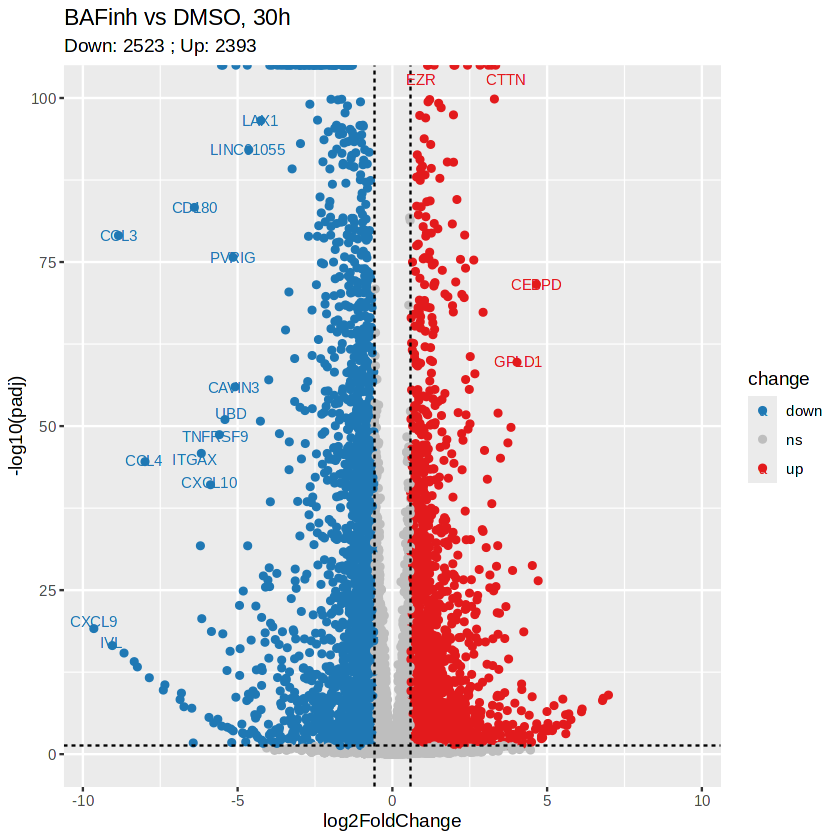

In [31]:
volcano(res, row.data,main="BAFinh vs DMSO, 30h")